In [1]:
import os, json
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from pygms import TargetIntensityMeasure, GroundMotionSelection

In [2]:
#np.random.seed(1)  # fixed seed for reproducibility

In [3]:
# load configuration file
with open('./example1.json','r') as f:
    job_config = json.load(f)

In [4]:
# create a target intensity measure
tgt_config = job_config.get('TargetIntensityMeasure')
my_tgt = TargetIntensityMeasure(tgt_config)
my_tgt.run_im_calculator()

USGS_GMM: GMM configured


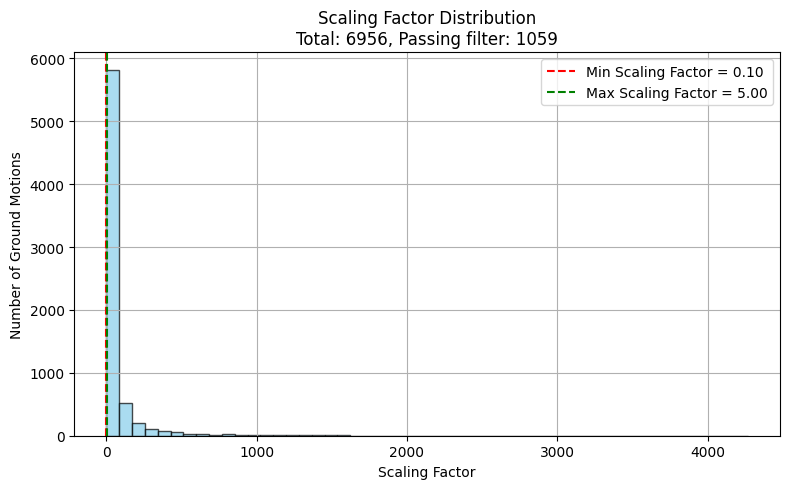

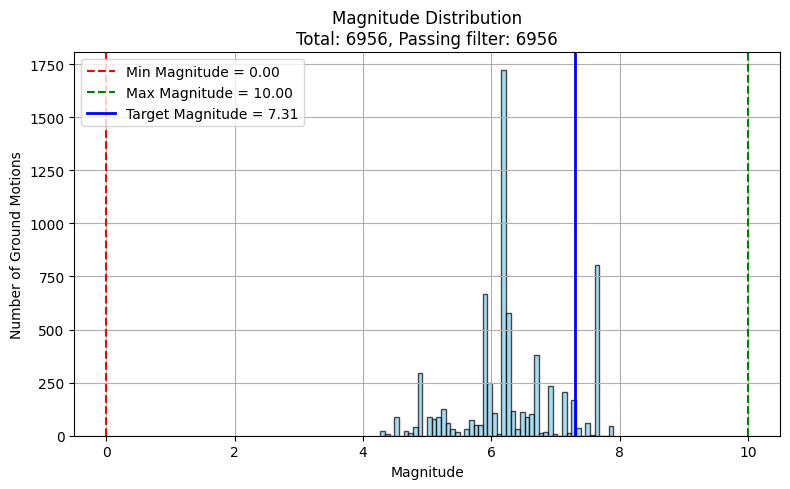

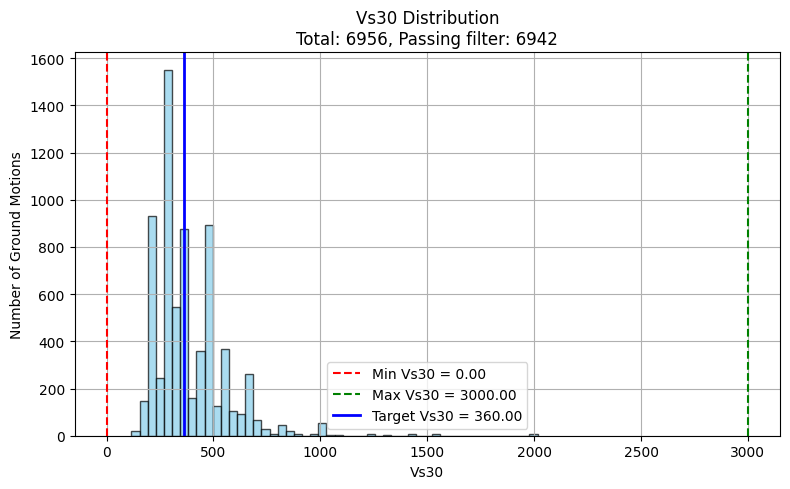

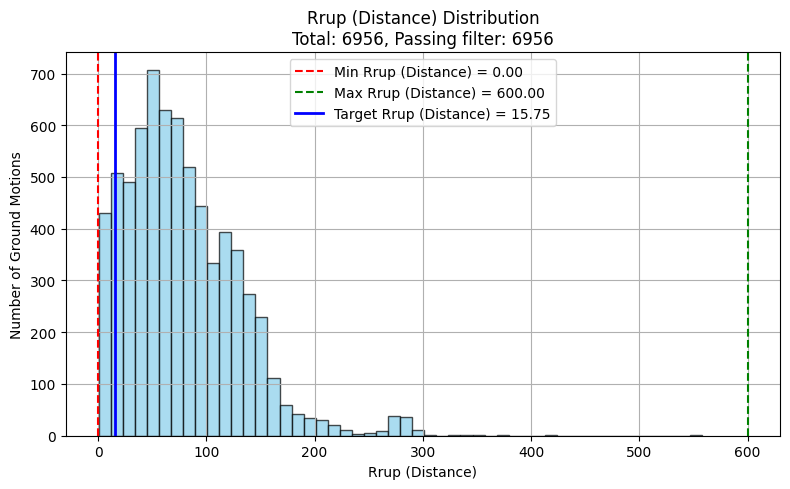

Total initial samples: 6956
Filtering summary:
After scaling filter: 1059
After magnitude filter: 1059
After Vs30 filter: 1059
After distance filter: 1059
Final accepted samples: 1059
GroundMotionSelection.optimize_selection: current total error: 0.003459.
GroundMotionSelection.optimize_selection: 1.00%.
GroundMotionSelection.optimize_selection: current total error: 0.003054.
GroundMotionSelection.optimize_selection: 2.00%.
GroundMotionSelection.optimize_selection: current total error: 0.002494.
GroundMotionSelection.optimize_selection: 3.00%.
GroundMotionSelection.optimize_selection: current total error: 0.002350.
GroundMotionSelection.optimize_selection: 4.00%.
GroundMotionSelection.optimize_selection: current total error: 0.002350.
GroundMotionSelection.optimize_selection: 5.00%.
GroundMotionSelection.optimize_selection: current total error: 0.002259.
GroundMotionSelection.optimize_selection: 6.00%.
GroundMotionSelection.optimize_selection: current total error: 0.001990.
GroundMotio

In [6]:
# ground motion selection
gms_config = job_config.get('GroundMotionSelection')
gms_config.update({'TargetType':tgt_config.get('TargetType')})
gms_config['Hazard']=tgt_config.get('Hazard')

my_gms = GroundMotionSelection(gms_config)
my_gms.generate_pseudo_im(my_tgt.im_target)
my_gms.initial_scanning(my_tgt.ims,my_tgt.cond_imv,my_tgt.cond_im_idx)
my_gms.optimize_selection(my_tgt.ims)

my_gms.export_selection(my_tgt.ims)

In [ ]:
# plot
# selected spectra over the full database period range (scaled), target only over the fitting periods
INK, MUTED, FAINT, HAIRLINE, ACCENT = '#1d1d1f', '#7a7a7a', '#d2d2d7', '#f0f0f0', '#0066cc'
plot_style = {
    'font.family': 'sans-serif',
    'font.sans-serif': ['SF Pro Display', 'Helvetica Neue', 'Arial', 'DejaVu Sans'],
    'font.size': 10,
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.labelcolor': '#333333', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'legend.frameon': False, 'legend.fontsize': 9,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

def style_axes(ax, title, subtitle):
    ax.grid(which='major', color=HAIRLINE, linewidth=0.8)
    ax.grid(which='minor', color='#f5f5f7', linewidth=0.5)
    ax.set_axisbelow(True)
    ax.tick_params(which='both', length=0)
    ax.set_title(title, loc='left', fontsize=13, fontweight='semibold', color=INK, pad=22)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED, va='bottom')

n_sel_periods = len(my_gms.selection_periods)
fit_periods = np.array(my_gms.selection_periods)
db_periods = np.array(my_gms.gmdb_periods)
sel_rows = [my_gms.gm_flag[x] for x in my_gms.selected_id]
sel_sa = my_gms.gmdb['SA'].iloc[sel_rows,:].to_numpy()*np.array(my_gms.gm_sf)[my_gms.selected_id][:,np.newaxis]
tgt_mean = np.array(my_gms.tgt_mean[0:n_sel_periods])
tgt_std = np.sqrt(np.diag(my_gms.tgt_cov))[0:n_sel_periods]
x_lim = [min(0.1, fit_periods.min()), db_periods.max()]
subtitle = '{} records, scaled · target over {:g}–{:g} s'.format(my_gms.num_rec, fit_periods.min(), fit_periods.max())

with plt.rc_context(plot_style):
    # response spectra
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.loglog(db_periods, sel_sa.T, color=FAINT, linewidth=0.6)
    if my_gms.tgt_type in ['CSD','CS']:
        ax.fill_between(fit_periods, np.exp(tgt_mean-tgt_std), np.exp(tgt_mean+tgt_std), color=ACCENT, alpha=0.08, linewidth=0, label='Target ±1σ')
    ax.loglog(fit_periods, np.exp(tgt_mean), color=ACCENT, linewidth=2.2, label='Target median')
    ax.loglog(db_periods, np.exp(np.mean(np.log(sel_sa),axis=0)), color=INK, linewidth=1.4, linestyle=(0,(4,3)), label='Selected geometric mean')
    ax.plot([], [], color=FAINT, linewidth=1.2, label='Selected records')
    ax.set_xlim(x_lim)
    ax.set_xlabel('Period, T (s)')
    ax.set_ylabel('Spectral acceleration, Sa (g)')
    ax.legend(loc='lower left')
    style_axes(ax, 'Response spectra', subtitle)
    fig.tight_layout()
    plt.show()

    # dispersion
    if my_gms.tgt_type in ['CSD','CS']:
        fig, ax = plt.subplots(figsize=(7.5, 4.0))
        ax.semilogx(fit_periods, tgt_std, color=ACCENT, linewidth=2.2, label='Target')
        ax.semilogx(db_periods, np.std(np.log(sel_sa),axis=0), color=INK, linewidth=1.4, linestyle=(0,(4,3)), label='Selected')
        ax.set_xlim(x_lim)
        ax.set_ylim(bottom=0)
        ax.set_xlabel('Period, T (s)')
        ax.set_ylabel('Standard deviation of ln Sa')
        ax.legend(loc='lower left')
        style_axes(ax, 'Dispersion', subtitle)
        fig.tight_layout()
        plt.show()

    # duration
    if my_gms.tgt_type in ['CSD']:
        ds_sel = np.sort(np.exp(my_gms.gmdb_imv[my_gms.selected_id,-1]))
        x = np.linspace(0, max(50, 1.2*ds_sel.max()), 300)
        fig, ax = plt.subplots(figsize=(7.5, 4.0))
        ax.plot(x[1:], norm.cdf(np.log(x[1:]), loc=my_gms.tgt_mean[-1], scale=np.sqrt(np.diag(my_gms.tgt_cov))[-1]),
                color=ACCENT, linewidth=2.2, label='Target')
        ax.step(ds_sel, np.arange(1,my_gms.num_rec+1)/my_gms.num_rec, where='post', color=INK, linewidth=1.4, label='Selected')
        ax.set_xlim(left=0)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel('Significant duration, Ds5-75 (s)')
        ax.set_ylabel('Cumulative probability')
        ax.legend(loc='lower right')
        style_axes(ax, 'Significant duration', '{} records'.format(my_gms.num_rec))
        fig.tight_layout()
        plt.show()